# 7.4 Обучение сети XOR / XOR 网络训练
Сеть 2 → 3 → 1, sigmoid в обоих слоях. Градиенты вычисляем вручную в NumPy.
使用 2 → 3 → 1 网络，两层均使用 sigmoid，在 NumPy 中手动计算梯度。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
blue, red = "#356AE6", "#D94F65"
np.set_printoptions(precision=5, suppress=True)

def sigmoid(x):
    return np.exp(-np.logaddexp(0.0, -np.asarray(x)))

In [2]:
X_all = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_all = np.array([[0.], [1.], [1.], [0.]])
rng = np.random.default_rng(0)
parameters = [rng.normal(size=(2, 3)), np.zeros((1, 3)),
              rng.normal(size=(3, 1)), np.zeros((1, 1))]
initial_parameters = [p.copy() for p in parameters]
print("Shapes:", [p.shape for p in parameters])

Shapes: [(2, 3), (1, 3), (3, 1), (1, 1)]


## Прямой и обратный проход / 前向与反向传播
$L=\frac12\mathrm{MSE}$. Производная sigmoid через её выход $a$: $a(1-a)$.
Все градиенты вычисляются до изменения весов. `y.size` учитывает усреднение в loss; здесь это число объектов batch.
先计算全部梯度，再更新权重。`y.size` 对应损失中的平均因子，在这个单输出网络中就是批次样本数。

In [3]:
def forward(X, parameters):
    W1, b1, W2, b2 = parameters
    Z1 = X @ W1 + b1
    A1 = sigmoid(Z1)
    Z2 = A1 @ W2 + b2
    prediction = sigmoid(Z2)
    return A1, prediction

In [4]:
def loss_gradients(X, y, parameters):
    W1, b1, W2, b2 = parameters
    A1, prediction = forward(X, parameters)
    loss = 0.5 * np.mean((prediction - y)**2)
    dZ2 = (prediction - y) * prediction * (1 - prediction) / y.size
    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)
    dZ1 = (dZ2 @ W2.T) * A1 * (1 - A1)
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0, keepdims=True)
    return loss, (dW1, db1, dW2, db2)

## Проверка градиентов / 梯度检查
Сравниваем backpropagation с центральной разностью для каждого веса и смещения до обучения.
训练前，对每个权重和偏置，将反向传播结果与中心差分进行比较。

In [5]:
def gradient_check(X, y, parameters, epsilon=1e-5):
    _, analytic = loss_gradients(X, y, parameters)
    errors = []
    for k, parameter in enumerate(parameters):
        numerical = np.zeros_like(parameter)
        for index in np.ndindex(parameter.shape):
            plus = [p.copy() for p in parameters]
            minus = [p.copy() for p in parameters]
            plus[k][index] += epsilon
            minus[k][index] -= epsilon
            lp = loss_gradients(X, y, plus)[0]
            lm = loss_gradients(X, y, minus)[0]
            numerical[index] = (lp - lm) / (2 * epsilon)
        errors.append(np.max(np.abs(numerical - analytic[k])))
    return np.array(errors)

gradient_errors = gradient_check(X_all, y_all, parameters)
print("Maximum absolute errors (W1, b1, W2, b2):")
for name, error in zip(["W1", "b1", "W2", "b2"], gradient_errors):
    print(f"{name}: {error:.3e}")

Maximum absolute errors (W1, b1, W2, b2):
W1: 1.441e-12
b1: 2.438e-12
W2: 2.078e-12
b2: 6.786e-13


## Обучение / 训练
20 000 эпох, `lr=0.1`, batch из двух объектов. В конце каждой эпохи вычисляем loss по всем четырём точкам, а не по последнему batch.
训练 20 000 轮，学习率 0.1，批次大小 2。每轮结束后，使用全部四个样本计算损失。

In [6]:
lr = 0.1
epochs = 20000
batch_size = 2
loss_history = [loss_gradients(X_all, y_all, parameters)[0]]
for epoch in range(epochs):
    order = rng.permutation(len(X_all))
    for start in range(0, len(X_all), batch_size):
        ids = order[start:start + batch_size]
        _, gradients = loss_gradients(X_all[ids], y_all[ids], parameters)
        for parameter, gradient in zip(parameters, gradients):
            parameter -= lr * gradient
    loss_history.append(loss_gradients(X_all, y_all, parameters)[0])
    if (epoch + 1) % 5000 == 0:
        print(f"Epoch {epoch + 1}: loss={loss_history[-1]:.6f}")

Epoch 5000: loss=0.124138
Epoch 10000: loss=0.025570


Epoch 15000: loss=0.003266
Epoch 20000: loss=0.001528


In [7]:
_, prediction = forward(X_all, parameters)
classes = (prediction >= 0.5).astype(int)
print("x1 x2 target prediction class")
for x, target, value, label in zip(X_all, y_all, prediction, classes):
    print(f"{x[0]:.0f}  {x[1]:.0f}    {target[0]:.0f}    {value[0]:.5f}    {label[0]}")
print(f"Loss: {loss_history[-1]:.6f}")
print(f"Accuracy on XOR table: {np.mean(classes == y_all):.0%}")

x1 x2 target prediction class
0  0    0    0.03020    0
0  1    1    0.94304    1
1  0    1    0.94548    1
1  1    0    0.07140    0
Loss: 0.001528
Accuracy on XOR table: 100%


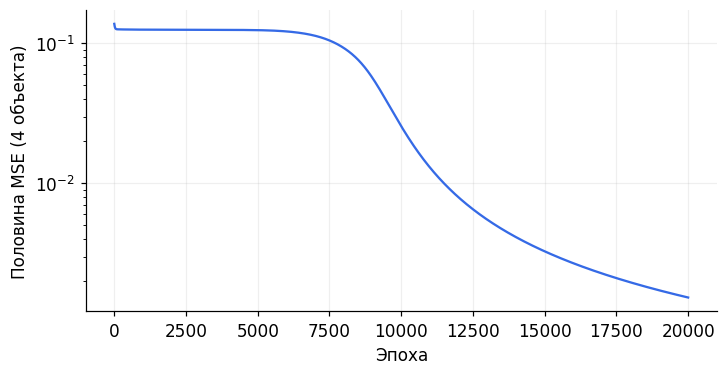

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.3), layout="constrained")
ax.semilogy(loss_history, color=blue)
ax.set(xlabel="Эпоха", ylabel="Половина MSE (4 объекта)")
ax.grid(alpha=0.2)
plt.show()

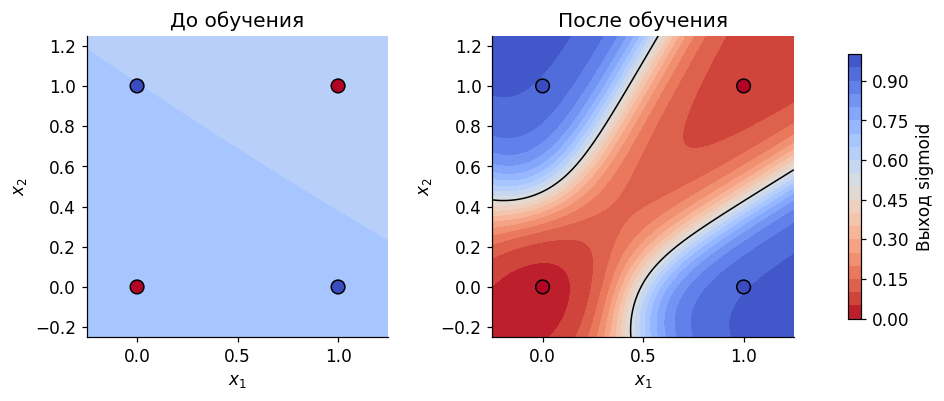

In [9]:
grid = np.linspace(-0.25, 1.25, 180)
gx, gy = np.meshgrid(grid, grid)
points = np.column_stack([gx.ravel(), gy.ravel()])
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6), layout="constrained")
for ax, params, name in zip(axes, [initial_parameters, parameters], ["До обучения", "После обучения"]):
    _, output = forward(points, params)
    surface = output.reshape(gx.shape)
    contour = ax.contourf(gx, gy, surface, levels=np.linspace(0, 1, 21), cmap="coolwarm_r")
    if surface.min() < 0.5 < surface.max():
        ax.contour(gx, gy, surface, levels=[0.5], colors="black", linewidths=1)
    ax.scatter(X_all[:, 0], X_all[:, 1], c=y_all.ravel(), cmap="coolwarm_r",
               vmin=0, vmax=1, edgecolors="black", s=80)
    ax.set(title=name, xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
fig.colorbar(contour, ax=axes, label="Выход sigmoid", shrink=0.8)
plt.show()

Обучены все четыре комбинации XOR. Точность 100% здесь означает воспроизведение таблицы, а не проверку обобщения. Цвет между точками показывает продолжение модели: правильные метки там не заданы.
四种 XOR 组合全部用于训练。这里的 100% 准确率表示学会真值表，并不代表验证了泛化能力；点之间的颜色仅是模型插值，这些位置没有给定真实标签。

[NumPy: Generator](https://numpy.org/doc/stable/reference/random/generator.html) — случайная инициализация и перемешивание / 随机初始化与打乱样本。